# Chuong 1. Cơ sở khoa học dữ liệu và công cụ xử lý dữ liệu
Mã lệnh của các ví dụ trong giáo trình Khoa học dữ liệu công trình, chạy tuần tự từ trên xuống.

[Mở trên Google Colab](https://colab.research.google.com/github/ngochoautc/khoa-hoc-du-lieu-cong-trinh/blob/main/notebooks/Chuong1.ipynb)

## TỔNG QUAN VỀ KHOA HỌC DỮ LIỆU TRONG KỸ THUẬT XÂY DỰNG

### Khái niệm khoa học dữ liệu

### Vai trò của khoa học dữ liệu trong ngành xây dựng

### Các bài toán ứng dụng điển hình trong kỹ thuật công trình

## MÔI TRƯỜNG LÀM VIỆC VÀ CÔNG CỤ

### Giới thiệu Google Colab

*Chỉ chạy trên Google Colab (gắn Google Drive).*

```
from google.colab import drive
import pandas as pd
drive.mount('/content/drive')
thu_muc = '/content/drive/MyDrive/du_lieu/'
df = pd.read_csv(thu_muc + 'do_vong.csv')    # doc tep
df.to_csv(thu_muc + 'ket_qua.csv', index=False)  # ghi tep
```

In [1]:
import sys
import numpy, pandas, matplotlib, scipy, sklearn
print("Python", sys.version.split()[0])
for m in (numpy, pandas, matplotlib, scipy, sklearn):
    print(m.__name__, m.__version__)

Python 3.12.9
numpy 2.5.4
pandas 3.0.6
matplotlib 3.11.2
scipy 1.18.1
sklearn 1.9.1


In [2]:
!pip install "pandas==3.0.*"

### Giới thiệu Jupyter Notebook

*Lệnh cài đặt, gõ trong cửa sổ dòng lệnh, không chạy trong Notebook.*

```
pip install notebook      # cai Jupyter Notebook
jupyter notebook          # khoi dong Jupyter Notebook
pip install jupyterlab    # cai JupyterLab
jupyter lab               # khoi dong JupyterLab
```

## PYTHON CHO TÍNH TOÁN KỸ THUẬT

### Giới thiệu về ngôn ngữ Python

### Các đặc điểm và cấu trúc cơ bản của Python trong tính toán kỹ thuật

In [3]:
n_nhip = 3           # so nhip
E = 2.0e5            # mo dun dan hoi thep (MPa)
dat = True           # ket qua kiem tra
ten = "D1"           # ten cau kien
print(type(n_nhip), type(E))
print(type(dat), type(ten))

<class 'int'> <class 'float'>
<class 'bool'> <class 'str'>


In [4]:
do_vong = [3.2, 4.1, 4.6, 3.9]    # do vong tai 4 diem (mm)
do_vong.append(2.8)               # them diem do thu 5
tiet_dien = (0.30, 0.60)          # (b, h) tiet dien (m)
dam = {"ten": "D1", "nhip": 12.0, "fc_MPa": 30}
print(do_vong[0], do_vong[-1], len(do_vong))
print("Lon nhat:", max(do_vong), "mm")
b, h = tiet_dien
print("Dien tich:", b * h, "m2")
print(dam["ten"], "nhip", dam["nhip"], "m")

3.2 2.8 5
Lon nhat: 4.6 mm
Dien tich: 0.18 m2
D1 nhip 12.0 m


In [5]:
print(do_vong * 2)
print([x * 2 for x in do_vong])

[3.2, 4.1, 4.6, 3.9, 2.8, 3.2, 4.1, 4.6, 3.9, 2.8]
[6.4, 8.2, 9.2, 7.8, 5.6]


In [6]:
print(6 / 3, -2**2, (-2)**2)
print(17 // 5, 17 % 5, (3 > 2) and not (1 > 2))

2.0 -4 4
3 2 True


In [7]:
rong = 1200    # k/c giua tim hai thanh ngoai cung (mm)
a = 150        # khoang cach thanh (mm)
so_khoang = rong // a
con_du = rong % a
print("So thanh:", so_khoang + 1, "- phan du:", con_du, "mm")
# gioi han 100-200 mm gia dinh cho vi du
print("Khoang cach dat yeu cau:", 100 <= a <= 200)

So thanh: 9 - phan du: 0 mm
Khoang cach dat yeu cau: True


*Mẫu cú pháp, không chạy trực tiếp.*

```
if dieu_kien:
    pass    # cac lenh khi dieu_kien dung
elif dieu_kien_khac:
    pass    # cac lenh khi dieu_kien_khac dung
else:
    pass    # cac lenh khi ca hai dieu kien sai
```

In [8]:
ung_suat = 185.0            # MPa, gia dinh
ung_suat_cho_phep = 210.0   # MPa, gia dinh
k = ung_suat / ung_suat_cho_phep
if k <= 0.9:
    ket_luan = "Dat"
elif k <= 1.0:
    ket_luan = "Dat, sat gioi han"
else:
    ket_luan = "Khong dat"
print(f"k = {k:.2f} -> {ket_luan}")

k = 0.88 -> Dat


In [9]:
L = 12.0                          # nhip dam (m)
tai_trong = [50, 75, 100, 125]    # luc tap trung (kN)
for P in tai_trong:
    M = P * L / 4
    print(f"P = {P} kN -> M = {M:.1f} kN.m")

P = 50 kN -> M = 150.0 kN.m
P = 75 kN -> M = 225.0 kN.m
P = 100 kN -> M = 300.0 kN.m
P = 125 kN -> M = 375.0 kN.m


In [10]:
M = 180e3            # mo men uon (N.m)
b = 0.30             # be rong (m)
sigma_cp = 12e6      # ung suat cho phep gia dinh (Pa)
h = 0.40
while 6 * M / (b * h**2) > sigma_cp:
    h = round(h + 0.05, 2)
print("Chieu cao chon:", h, "m")
print("Ung suat:", round(6 * M / (b * h**2) / 1e6, 2), "MPa")

Chieu cao chon: 0.55 m
Ung suat: 11.9 MPa


In [11]:
def tinh_momen_lon_nhat(P, L):
    """Mo men lon nhat dam gian don, luc tap trung
    giua nhip. P (kN), L (m) -> M (kN.m)."""
    return P * L / 4

M_max = tinh_momen_lon_nhat(100, 12.0)
print(f"Mo men lon nhat M = {M_max:.1f} kN.m")

Mo men lon nhat M = 300.0 kN.m


*Nội dung tệp ket_cau.py; tạo tệp này cạnh Notebook trước khi import.*

```
# Tep ket_cau.py
def tinh_momen_lon_nhat(P, L):
    """P (kN), L (m) -> M (kN.m)."""
    return P * L / 4

# Trong Notebook (cung thu muc voi ket_cau.py)
from ket_cau import tinh_momen_lon_nhat
M_max = tinh_momen_lon_nhat(100, 12.0)
```

In [12]:
import math
print(0.1 + 0.2 == 0.3, 0.1 + 0.2)
print(math.isclose(0.1 + 0.2, 0.3))

False 0.30000000000000004
True


### Các thư viện cơ bản trong Python cho bài toán xây dựng

In [13]:
import numpy as np

nhip = np.array([24.0, 33.0, 33.0, 42.0])   # nhip (m)
do_vong = np.array([[3.2, 4.1, 3.0],   # do vong (mm):
                    [3.5, 4.4, 3.1]])  # 2 dot x 3 diem
x = np.linspace(0, 12, 5)        # 5 diem chia deu dam 12 m
print(nhip.ndim, nhip.shape, nhip.dtype)
print(do_vong.ndim, do_vong.shape)
print(x)
print(np.arange(0, 1.0, 0.25))
print(np.zeros((2, 3)))

1 (4,) float64
2 (2, 3)
[ 0.  3.  6.  9. 12.]
[0.   0.25 0.5  0.75]
[[0. 0. 0.]
 [0. 0. 0.]]


In [14]:
print(nhip[0], nhip[-1])        # phan tu dau va cuoi
print(nhip[1:3])                # phan tu thu 2 va thu 3
print(do_vong[1, 2])            # dot do 2, diem 3
print(do_vong[:, 1])            # diem 2 cua ca hai dot do
print(do_vong[0])               # toan bo dot do 1

24.0 42.0
[33. 33.]
3.1
[4.1 4.4]
[3.2 4.1 3. ]


In [15]:
b = 0.30                             # be rong (m)
h = np.array([0.45, 0.50, 0.55, 0.60, 0.65])  # cao (m)
M = 180e3                            # mo men (N.m)
W = b * h**2 / 6                     # mo men khang uon (m3)
sigma = M / W / 1e6                  # ung suat (MPa)
print(np.round(sigma, 2))

[17.78 14.4  11.9  10.    8.52]


In [16]:
M = np.array([[420., 760., 980., 1040.],  # tinh tai KC
              [ 60., 110., 140.,  150.],  # lop phu
              [380., 690., 890.,  950.]]) # hoat tai
gamma = np.array([[1.25], [1.50], [1.75]])  # 3 x 1
M_tt = (gamma * M).sum(axis=0)    # kN.m, cong theo cot
print(M.shape, gamma.shape)
print(M_tt)

(3, 4) (3, 1)
[1280.  2322.5 2992.5 3187.5]


In [17]:
vuot = sigma > 12.0
print(vuot)
print("Chieu cao khong dat:", h[vuot], "m")
print("Vi tri:", np.where(vuot)[0])

[ True  True False False False]
Chieu cao khong dat: [0.45 0.5 ] m
Vi tri: [0 1]


In [18]:
print(round(do_vong.mean(), 2))        # trung binh toan bo
print(do_vong.mean(axis=0))            # trung binh tung diem do
print(do_vong.max(axis=1))             # lon nhat moi dot do
print(np.argmax(do_vong[0]))           # vi tri max dot 1
print(round(do_vong[1].std(ddof=1), 3))

3.55
[3.35 4.25 3.05]
[4.1 4.4]
1
0.666


In [19]:
k1, k2 = 30000.0, 20000.0           # do cung tang (kN/m)
K = np.array([[k1 + k2, -k2],
              [-k2,      k2]])
F = np.array([10.0, 20.0])          # luc ngang (kN)
u = np.linalg.solve(K, F)           # chuyen vi (m)
print(np.round(u * 1000, 3), "mm")
print(np.allclose(K @ u, F))        # kiem tra K u = F

[1. 2.] mm
True


In [20]:
rng = np.random.default_rng(42)
mau = rng.normal(38.5, 3.2, size=5)
print(np.round(mau, 1))

[39.5 35.2 40.9 41.5 32.3]


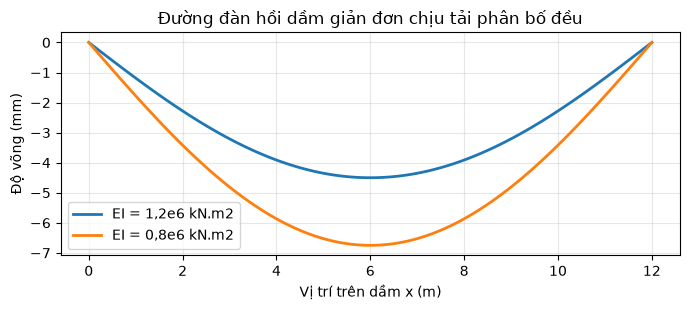

In [21]:
import numpy as np
import matplotlib.pyplot as plt

L, q = 12.0, 20.0                    # nhip (m), q (kN/m)
x = np.linspace(0, L, 121)
fig, ax = plt.subplots(figsize=(7, 3.2))
for EI, nhan in [(1.2e6, 'EI = 1,2e6 kN.m2'),
                 (0.8e6, 'EI = 0,8e6 kN.m2')]:
    y = q * x * (L**3 - 2*L*x**2 + x**3) / (24*EI) * 1000  # mm
    ax.plot(x, -y, linewidth=2, label=nhan)
ax.set_xlabel('Vị trí trên dầm x (m)')
ax.set_ylabel('Độ võng (mm)')
ax.set_title('Đường đàn hồi dầm giản đơn chịu tải phân bố đều')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig('do_vong_dam.png', dpi=300)

## GIỚI THIỆU VỀ PANDAS

### Tổng quan về pandas

### Cấu trúc dữ liệu cơ bản trong pandas

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

s = pd.Series([20.1, 9.5, 38.1, 23.5, 14.1],
              index=["C01", "C02", "C03", "C04", "C05"],
              name="Độ võng (mm)")
print(s)
print("s['C03'] =", s["C03"], "mm")
print(pd.Series(["C01", "C02"]).dtype)   # chuoi
print(pd.Series([1.5, "C01"]).dtype)     # tron so va chuoi

C01    20.1
C02     9.5
C03    38.1
C04    23.5
C05    14.1
Name: Độ võng (mm), dtype: float64
s['C03'] = 38.1 mm
str
object


In [23]:
ma = [f"C{i:02d}" for i in range(1, 21)]
L1, L2 = "Dầm BTCT", "Dầm BTCT DƯL"
L3, L4 = "Dầm thép", "Dầm liên hợp"
loai = [L2, L1, L3, L4, L2, L2, L1, L4, L2, L1,
        L3, L2, L4, L2, L1, L2, L3, L4, L2, L1]
nhip = [33, 18, 42, 36, 24, 33, 15, 40, 38, 21,
        45, 30, 33, 40, 12, 27, 35, 42, 33, 18]        # m
nam = [2008, 1985, 1978, 2012, 2001, 2015, 1992,
       2018, 2010, 1988, 1982, 2005, 1998, 2020,
       1979, 1996, 1990, 2006, 2002, 1995]
cstt = [83, 55, 44, 73, 74, 90, 64, 89, 85, 58,
        61, 76, 71, 99, 53, 71, 58, 78, 69, 65]
vong = [20.1, 9.5, 38.1, 23.5, 14.1, 17.7, 7.8, 22.2,
        21.6, 10.3, 42.5, np.nan, 21.3, 20.6, 6.0,
        16.9, 30.3, 29.1, 17.6, 9.8]                   # mm
df = pd.DataFrame({"Loại": loai, "Nhịp (m)": nhip,
                   "Năm XD": nam, "CSTT": cstt,
                   "Võng (mm)": vong},
                  index=pd.Index(ma, name="Mã cầu"))
print(df.shape)
print(df.head())

(20, 5)
                Loại  Nhịp (m)  Năm XD  CSTT  Võng (mm)
Mã cầu                                                 
C01     Dầm BTCT DƯL        33    2008    83       20.1
C02         Dầm BTCT        18    1985    55        9.5
C03         Dầm thép        42    1978    44       38.1
C04     Dầm liên hợp        36    2012    73       23.5
C05     Dầm BTCT DƯL        24    2001    74       14.1


### Các chức năng chính của pandas trong phân tích dữ liệu

In [24]:
df.info()

<class 'pandas.DataFrame'>
Index: 20 entries, C01 to C20
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Loại       20 non-null     str    
 1   Nhịp (m)   20 non-null     int64  
 2   Năm XD     20 non-null     int64  
 3   CSTT       20 non-null     int64  
 4   Võng (mm)  19 non-null     float64
dtypes: float64(1), int64(3), str(1)
memory usage: 960.0+ bytes


In [25]:
df["Tuổi (năm)"] = 2026 - df["Năm XD"]
print(df.loc["C03", ["Loại", "Tuổi (năm)"]])
print(df.iloc[0:2, 0:3])
dk = (df["Nhịp (m)"] > 30) & (df["Loại"] == "Dầm BTCT DƯL")
print(df.loc[dk, ["Nhịp (m)", "CSTT"]])

Loại          Dầm thép
Tuổi (năm)          48
Name: C03, dtype: object
                Loại  Nhịp (m)  Năm XD
Mã cầu                                
C01     Dầm BTCT DƯL        33    2008
C02         Dầm BTCT        18    1985
        Nhịp (m)  CSTT
Mã cầu                
C01           33    83
C06           33    90
C09           38    85
C14           40    99
C19           33    69


In [26]:
tam = df.copy()
con = tam[tam["Nhịp (m)"] > 40]   # 3 cau: C03, C11, C18
con["CSTT"] = 0                    # chi sua 'con'
print("Sau khi sua 'con':", tam.loc["C11", "CSTT"])
tam.loc[tam["Nhịp (m)"] > 40, "CSTT"] = 0
print("Sau khi gan bang loc:", tam.loc["C11", "CSTT"])

Sau khi sua 'con': 61
Sau khi gan bang loc: 0


In [27]:
print(df.isna().sum().to_dict())
v = df["Võng (mm)"]
print("pandas mean:", round(v.mean(), 2), "mm, n =", v.count())
print("numpy mean :", np.mean(v.to_numpy()))
print("So hang sau dropna:", len(df.dropna()))

{'Loại': 0, 'Nhịp (m)': 0, 'Năm XD': 0, 'CSTT': 0, 'Võng (mm)': 1, 'Tuổi (năm)': 0}
pandas mean: 19.95 mm, n = 19
numpy mean : nan
So hang sau dropna: 19


### Ứng dụng pandas trong kỹ thuật công trình

### Cài đặt pandas

*Lệnh cài đặt, gõ trong cửa sổ dòng lệnh (trên Colab thêm % ở đầu: %pip install ...).*

```
pip install -U "pandas>=3.0"
conda install -c conda-forge "pandas>=3.0"
%pip install -U "pandas>=3.0"     # o ma lenh Colab
```

In [28]:
import sys
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)

Python: 3.12.9
pandas: 3.0.6


## PHÂN TÍCH VÀ TRỰC QUAN HÓA DỮ LIỆU VỚI PANDAS

### Khám phá dữ liệu

### Thống kê mô tả với pandas

In [29]:
cot = ["Nhịp (m)", "Tuổi (năm)", "CSTT", "Võng (mm)"]
print(df[cot].describe().round(2))

       Nhịp (m)  Tuổi (năm)   CSTT  Võng (mm)
count     20.00       20.00  20.00      19.00
mean      30.75       27.00  70.80      19.95
std        9.80       12.83  14.01       9.87
min       12.00        6.00  44.00       6.00
25%       23.25       17.50  60.25      12.20
50%       33.00       26.50  71.00      20.10
75%       38.50       36.50  79.25      22.85
max       45.00       48.00  99.00      42.50


In [30]:
n = df["Nhịp (m)"]
print("Trung vi nhip:", n.median(), "m")
print("Mot nhip:", n.mode().tolist(), "m")
print("Mot loai:", df["Loại"].mode().tolist())
print("std pandas (ddof=1):", round(n.std(), 3), "m")
print("std numpy (ddof=0):", round(np.std(n.to_numpy()), 3),
      "m")
print(df["Loại"].describe())

Trung vi nhip: 33.0 m
Mot nhip: [33] m
Mot loai: ['Dầm BTCT DƯL']
std pandas (ddof=1): 9.803 m
std numpy (ddof=0): 9.554 m
count               20
unique               4
top       Dầm BTCT DƯL
freq                 8
Name: Loại, dtype: object


In [31]:
print(df[cot].corr().round(2))
print(df[cot].corr(method="spearman").round(2))

            Nhịp (m)  Tuổi (năm)  CSTT  Võng (mm)
Nhịp (m)        1.00       -0.40  0.39       0.89
Tuổi (năm)     -0.40        1.00 -0.95       0.03
CSTT            0.39       -0.95  1.00      -0.02
Võng (mm)       0.89        0.03 -0.02       1.00
            Nhịp (m)  Tuổi (năm)  CSTT  Võng (mm)
Nhịp (m)        1.00       -0.34  0.35       0.94
Tuổi (năm)     -0.34        1.00 -0.96      -0.18
CSTT            0.35       -0.96  1.00       0.19
Võng (mm)       0.94       -0.18  0.19       1.00


### Thống kê theo nhóm với groupby

In [32]:
df["L/f"] = df["Nhịp (m)"] * 1000 / df["Võng (mm)"]
bang = df.groupby("Loại").agg(
    so_cau=("Nhịp (m)", "size"),
    nhip_tb=("Nhịp (m)", "mean"),
    tuoi_tb=("Tuổi (năm)", "mean"),
    cstt_tb=("CSTT", "mean"),
    Lf_tb=("L/f", "mean"))
print(bang.round(1))

              so_cau  nhip_tb  tuoi_tb  cstt_tb   Lf_tb
Loại                                                   
Dầm BTCT           5     16.8     38.2     59.0  1938.7
Dầm BTCT DƯL       8     32.2     18.9     80.9  1768.9
Dầm liên hợp       4     37.8     17.5     77.8  1581.6
Dầm thép           3     40.7     42.7     54.3  1105.4


### Vẽ biểu đồ bằng pandas

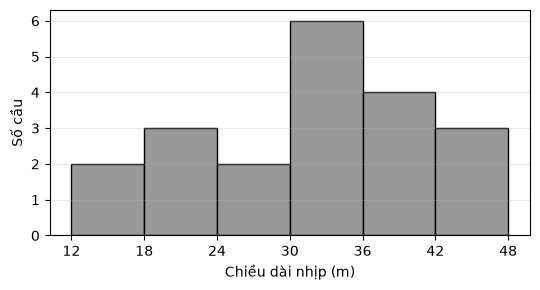

In [33]:
ax = df["Nhịp (m)"].plot.hist(bins=range(12, 49, 6),
                              color="0.6", edgecolor="k")
ax.set_xlabel("Chiều dài nhịp (m)")
ax.set_ylabel("Số cầu")
ax.set_xticks(range(12, 49, 6))
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(alpha=0.3, axis="y")
ax.figure.set_size_inches(5.5, 3.0)
ax.figure.tight_layout()

{'Dầm BTCT DƯL': 8, 'Dầm BTCT': 5, 'Dầm liên hợp': 4, 'Dầm thép': 3}


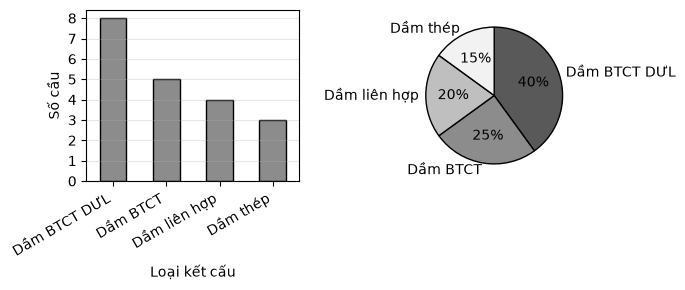

In [34]:
dem = df["Loại"].value_counts()
print(dem.to_dict())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.0))
dem.plot.bar(ax=ax1, color="0.55", edgecolor="k", rot=30)
plt.setp(ax1.get_xticklabels(), ha="right")
ax1.set_xlabel("Loại kết cấu")
ax1.set_ylabel("Số cầu")
ax1.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax1.grid(alpha=0.3, axis="y")
mau = ["0.35", "0.55", "0.75", "0.95"]
dem.plot.pie(ax=ax2, autopct="%1.0f%%", colors=mau,
             startangle=90, counterclock=False,
             wedgeprops={"edgecolor": "k"})
ax2.set_ylabel("")
fig.tight_layout()

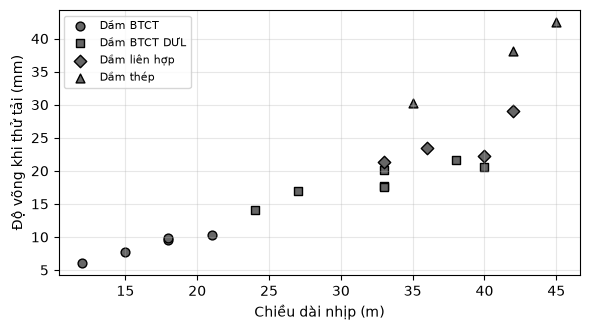

In [35]:
ky_hieu = {L1: "o", L2: "s", L3: "^", L4: "D"}
fig, ax = plt.subplots(figsize=(6, 3.4))
for ten, g in df.groupby("Loại"):
    g.plot.scatter(x="Nhịp (m)", y="Võng (mm)", ax=ax,
                   marker=ky_hieu[ten], s=40, color="0.4",
                   edgecolor="k", label=ten)
ax.set_xlabel("Chiều dài nhịp (m)")
ax.set_ylabel("Độ võng khi thử tải (mm)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

## TRỰC QUAN HÓA DỮ LIỆU CƠ BẢN

### Quy trình trực quan hóa dữ liệu

### Các dạng biểu đồ thường dùng trong kỹ thuật xây dựng

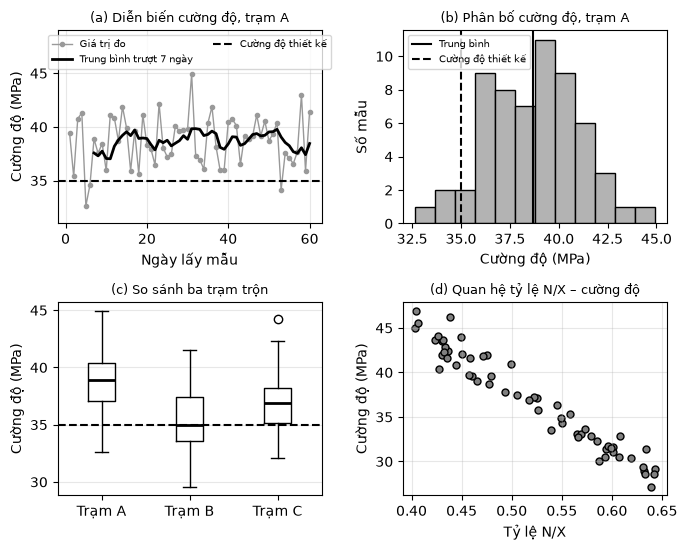

In [36]:
rng = np.random.default_rng(42)
tram_A = rng.normal(38.5, 3.0, 60)      # MPa
tram_B = rng.normal(35.8, 3.6, 60)
tram_C = rng.normal(37.2, 2.4, 60)
ngay = np.arange(1, 61)
tbt = np.convolve(tram_A, np.ones(7) / 7, mode="valid")
fig, ax = plt.subplots(2, 2, figsize=(7, 5.6))
# (a) Bieu do duong: dien bien theo thoi gian
a = ax[0, 0]
a.plot(ngay, tram_A, color="0.6", lw=1, marker=".",
       label="Giá trị đo")
a.plot(ngay[6:], tbt, "k-", lw=2,
       label="Trung bình trượt 7 ngày")
a.axhline(35, color="k", ls="--", label="Cường độ thiết kế")
a.set_xlabel("Ngày lấy mẫu")
a.set_ylabel("Cường độ (MPa)")
a.set_title("(a) Diễn biến cường độ, trạm A", fontsize=9)
a.set_ylim(31, 49)
a.legend(fontsize=7, loc="upper center", ncol=2)
a.grid(alpha=0.3)
# (b) Histogram: phan bo cuong do
b = ax[0, 1]
b.hist(tram_A, bins=12, color="0.7", edgecolor="k")
b.axvline(tram_A.mean(), color="k", label="Trung bình")
b.axvline(35, color="k", ls="--", label="Cường độ thiết kế")
b.set_xlabel("Cường độ (MPa)")
b.set_ylabel("Số mẫu")
b.set_title("(b) Phân bố cường độ, trạm A", fontsize=9)
b.legend(fontsize=7, loc="upper left")
# (c) Bieu do hop: so sanh ba tram tron
c = ax[1, 0]
c.boxplot([tram_A, tram_B, tram_C],
          tick_labels=["Trạm A", "Trạm B", "Trạm C"],
          medianprops={"color": "k", "lw": 2})
c.axhline(35, color="k", ls="--")
c.set_ylabel("Cường độ (MPa)")
c.set_title("(c) So sánh ba trạm trộn", fontsize=9)
c.grid(alpha=0.3, axis="y")
# (d) Bieu do phan tan: quan he hai bien
nx = rng.uniform(0.40, 0.65, 60)
cd = 73.8 - 70.9 * nx + rng.normal(0, 1.2, 60)
d = ax[1, 1]
d.scatter(nx, cd, s=25, color="0.5", edgecolor="k")
d.set_xlabel("Tỷ lệ N/X")
d.set_ylabel("Cường độ (MPa)")
d.set_title("(d) Quan hệ tỷ lệ N/X – cường độ", fontsize=9)
d.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [37]:
from scipy import stats
duoi = np.flatnonzero(tram_A < 35)
print("Trung binh tram A:", round(tram_A.mean(), 2), "MPa")
print("Ngay < 35 MPa:", (duoi + 1).tolist(),
      np.round(tram_A[duoi], 2).tolist())
print("Trung binh truot:", round(tbt.min(), 2), "-",
      round(tbt.max(), 2), "MPa")
print("He so bat doi xung:", round(stats.skew(tram_A), 2))
p_sw = stats.shapiro(tram_A).pvalue
print("Shapiro-Wilk p =", round(p_sw, 2))
for ten, x in [("A", tram_A), ("B", tram_B), ("C", tram_C)]:
    print(f"Tram {ten}: trung vi {np.median(x):.1f} MPa,"
          f" IQR {np.subtract(*np.percentile(x, [75, 25])):.1f}"
          f" MPa")
print("r(N/X, cuong do) =", round(np.corrcoef(nx, cd)[0, 1], 2))

Trung binh tram A: 38.7 MPa
Ngay < 35 MPa: [5, 6, 53] [32.65, 34.59, 34.13]
Trung binh truot: 37.03 - 39.84 MPa
He so bat doi xung: -0.07
Shapiro-Wilk p = 0.95
Tram A: trung vi 38.9 MPa, IQR 3.4 MPa
Tram B: trung vi 35.0 MPa, IQR 3.8 MPa
Tram C: trung vi 36.9 MPa, IQR 3.0 MPa
r(N/X, cuong do) = -0.97


N/X        -0.67
Xi măng     0.65
Phụ gia     0.07
Tuổi        0.75
Cường độ    1.00
Name: Cường độ, dtype: float64


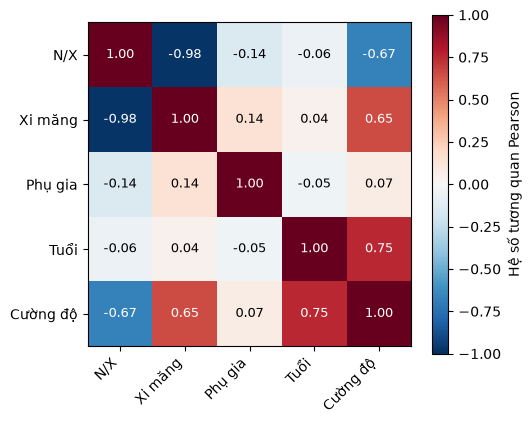

In [38]:
rng2 = np.random.default_rng(16)
m = 60
nx2 = rng2.uniform(0.40, 0.65, m)
tuoi = rng2.choice([7, 28], m)
cd28 = 73.8 - 70.9 * nx2 + rng2.normal(0, 1.2, m)
cp = pd.DataFrame({
    "N/X": nx2,
    "Xi măng": 170 / nx2 + rng2.normal(0, 8, m),   # kg/m3
    "Phụ gia": rng2.uniform(0.5, 2.0, m),          # % XM
    "Tuổi": tuoi,                                  # ngay
    "Cường độ": cd28 * np.where(tuoi == 7, 0.7, 1.0)})
R = cp.corr()
print(R["Cường độ"].round(2))
fig, ax = plt.subplots(figsize=(5.4, 4.4))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(5), R.columns, rotation=45, ha="right")
ax.set_yticks(range(5), R.columns)
for i in range(5):
    for j in range(5):
        mau = "white" if abs(R.iloc[i, j]) > 0.6 else "black"
        ax.text(j, i, f"{R.iloc[i, j]:.2f}", ha="center",
                va="center", fontsize=9, color=mau)
fig.colorbar(im, ax=ax, label="Hệ số tương quan Pearson")
fig.tight_layout()

## BÀI TẬP THỰC HÀNH

In [39]:
def k_dam(EI, l):
    return EI / l**3 * np.array([[ 12,    6*l,  -12,    6*l],
                                 [6*l, 4*l**2, -6*l, 2*l**2],
                                 [-12,   -6*l,   12,   -6*l],
                                 [6*l, 2*l**2, -6*l, 4*l**2]])